# Within-clip rollout V2 — SimSiam timing and sequential interactions

24 saved origins,5 fresh paired draws,8 minibatches. Timing replication first; two-update interactions and a causal greedy comparison only after the unlabeled gate passes.


## Progress and ETA (Stockholm)

```json
{
  "state": "gated",
  "stage": "Timing replication complete; pair stage gated",
  "completed_a": 600,
  "total_a": 600,
  "completed_b": 0,
  "total_b": 840,
  "updated": "2026-11-19T19:21:42.587988+01:00",
  "eta": null,
  "eta_note": "Stage A estimate until timing gate is decided; then includes conditional two-update stage. Early default timing is provisional.",
  "smoke": false
}
```


## What is being tested

Stage A: Skip and single conservative updates at positions0,2,5,7:600 branches. Stage B: six exact two-update pairs plus one causal greedy reference:840 additional branches, conditional.

All outcomes are measured on untouched local, historical and global banks. LiDAR uses eight mild views; retrieval, losses, rank and variance remain separate. Fixed external probes are evaluation only. Exact model/optimizer/BN/AMP/RNG restoration and a repeated two-update preflight must pass.

Independent-draw oracles choose on four draws and evaluate the fifth. The best fixed timing/pair is chosen on other source seeds. Report endpoint and time-average health separately; no semantic labels determine the stage gate.

Interactions use **Iij = Qij − Qi − Qj + Qskip**, paired by draw. The additive selector and sequence oracle are retrospective diagnostics. The greedy baseline observes only prior frames and the current eligible minibatch, spends exactly two updates, and records its monitoring cost. A favorable oracle is not evidence of a deployed MPC.

Nine external states are fixed before collection, balanced across three source seeds and early/middle/late stages. Reusing V1 origins tests fresh future stochasticity, not new independent training trajectories.


## Stage A Summary

```json
{
  "timing": {
    "lidar": {
      "gain_vs_fixed": {
        "mean": 0.0002835120043778616,
        "seed_means": {
          "2026": 0.0008044170092790459,
          "2027": 0.0006222095936569971,
          "2028": -0.0005760905898024582
        },
        "seed_bootstrap95": [
          -0.0005760905898024582,
          0.0008044170092790459
        ]
      },
      "gain_vs_skip": {
        "mean": 0.0026783577717731134,
        "seed_means": {
          "2026": 0.0006742844719977547,
          "2027": 0.002900289532425937,
          "2028": 0.004460499310895649
        },
        "seed_bootstrap95": [
          0.0006742844719977546,
          0.004460499310895649
        ]
      },
      "action_frequency": {
        "single7": 24,
        "single5": 35,
        "single0": 47,
        "single2": 14
      },
      "winner_agreement": 0.30833333333333335,
      "mean_within_state_draw_sd": 0.0023689029368638027,
      "mean_timing_range": 0.003580179925350239
    },
    "retrieval_margin": {
      "gain_vs_fixed": {
        "mean": 6.933556869626045e-06,
        "seed_means": {
          "2026": 7.95908272266388e-06,
          "2027": 9.485147893428803e-06,
          "2028": 3.3564399927854536e-06
        },
        "seed_bootstrap95": [
          3.356439992785453e-06,
          9.485147893428803e-06
        ]
      },
      "gain_vs_skip": {
        "mean": 3.6876027782758077e-06,
        "seed_means": {
          "2026": -1.609325408935547e-07,
          "2027": 1.2940168380737304e-05,
          "2028": -1.716427505016327e-06
        },
        "seed_bootstrap95": [
          -1.716427505016327e-06,
          1.2940168380737304e-05
        ]
      },
      "action_frequency": {
        "single5": 34,
        "single0": 39,
        "single7": 21,
        "single2": 26
      },
      "winner_agreement": 0.3541666666666667,
      "mean_within_state_draw_sd": 1.418528955139036e-05,
      "mean_timing_range": 2.2828718647361294e-05
    }
  },
  "semantic": {
    "lidar": {
      "mean": -0.00021184277413209803,
      "seed_means": {
        "2026": 5.212178928871934e-05,
        "2027": -0.00028240334295958437,
        "2028": -0.00040524676872542907
      },
      "seed_bootstrap95": [
        -0.0004052467687254291,
        5.212178928871934e-05
      ]
    },
    "retrieval_margin": {
      "mean": -3.040658699811147e-05,
      "seed_means": {
        "2026": -2.6237991780201757e-05,
        "2027": -0.00011135352641739408,
        "2028": 4.6371757203261423e-05
      },
      "seed_bootstrap95": [
        -0.00011135352641739408,
        4.6371757203261423e-05
      ]
    }
  },
  "interpretation": "All timing selections use independent augmentation draws. Only3 source trajectories; source states reused from V1. Semantic labels do not enter the timing gate."
}
```


## Gate A

```json
{
  "passed": false,
  "routes": [
    {
      "metric": "lidar",
      "passed": false,
      "minimum_gain": 0.01,
      "observed": {
        "mean": 0.0002835120043778616,
        "seed_means": {
          "2026": 0.0008044170092790459,
          "2027": 0.0006222095936569971,
          "2028": -0.0005760905898024582
        },
        "seed_bootstrap95": [
          -0.0005760905898024582,
          0.0008044170092790459
        ]
      }
    },
    {
      "metric": "retrieval_margin",
      "passed": false,
      "minimum_gain": 2e-05,
      "observed": {
        "mean": 6.933556869626045e-06,
        "seed_means": {
          "2026": 7.95908272266388e-06,
          "2027": 9.485147893428803e-06,
          "2028": 3.3564399927854536e-06
        },
        "seed_bootstrap95": [
          3.356439992785453e-06,
          9.485147893428803e-06
        ]
      }
    }
  ],
  "labels_used": false
}
```


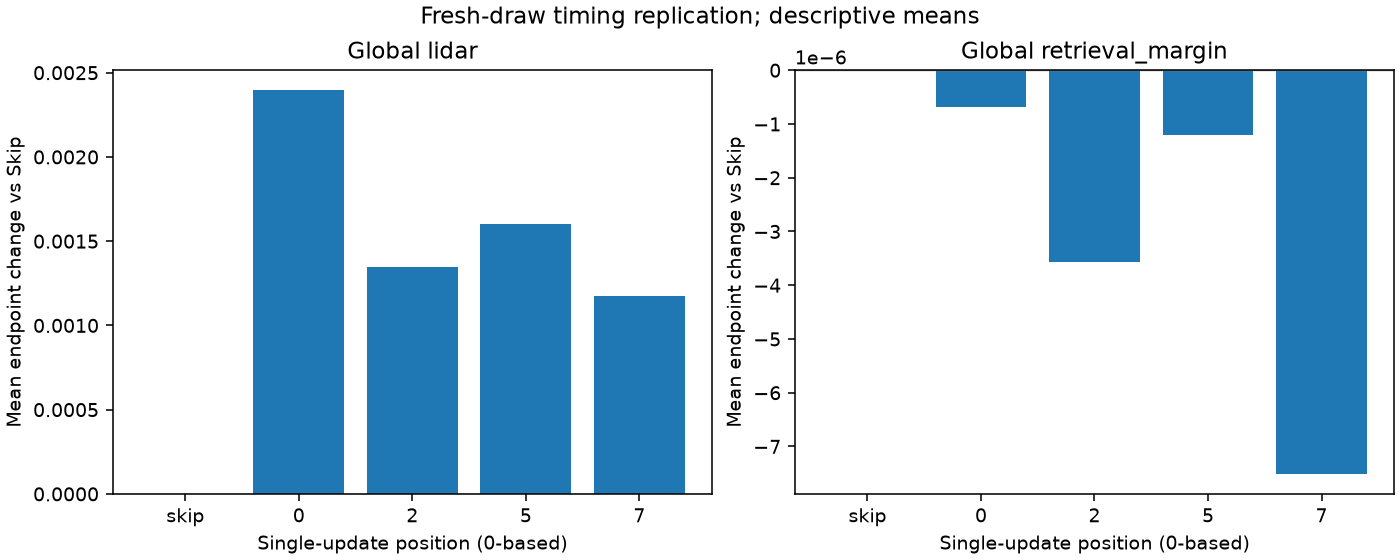